# Experimental: 3-D wind projected onto a cross-section plane

**This is an experimental example.** It reproduces the Metview gallery example [Cross Section 3D Parallel Wind](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_wind_3d.html) with earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. The horizontal part (the line and the regridding onto the line) uses the new `earthkit.geo.polyline` module, whose interface may still change. The computations on the model levels (the pressure on the hybrid levels, the vertical velocity in m/s and the interpolation to pressure levels) use `earthkit.meteo`.

The plot shows arrows in the vertical plane under a line from (48.32°N, 1.18°E) to (40.43°N, 2.44°E), which goes roughly southwards across the Pyrenees. The horizontal component of each arrow is the **wind component along the line**, in m/s: it is positive in the direction of travel, i.e. southwards. The vertical component is the **vertical velocity** `w` in m/s, positive upwards, multiplied by 50 so that it is visible (as in Metview). The arrows are at fixed pressure levels, from 1000 to 250 hPa every 25 hPa.

This is the simplified version of the [raw notebook](../raw/cross_section_wind_3d.ipynb). It uses the `cross_section()`, `wind_components()` and model-level helpers from [../xsection.py](../xsection.py) instead of the hand-written regridding, projection, vertical interpolation and Xarray steps.

The notebook reads a GRIB file. It contains forecast data on 91 hybrid model levels for 2011-12-15 12 UTC, step 24 h.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import sys

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline
from earthkit.meteo import vertical, wind

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import (
    cross_section,
    hybrid_coefficients,
    model_to_pressure,
    pressure_on_model_levels,
    surface_pressure,
    wind_components,
)

## Load the data

The file contains the wind components `u` and `v`, the pressure velocity `w` (omega, in Pa/s) and the temperature `t` on the 91 hybrid model levels, and the logarithm of the surface pressure `lnsp`, which has a single field. It is a GRIB2 file on a regular 0.1° latitude-longitude grid over the area 40–48.5°N, 1–2.5°E. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "joachim_ml.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

joachim_ml.grib:   0%|          | 0.00/1.29M [00:00<?, ?B/s]

365 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,u,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
1,v,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
2,w,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
3,t,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
4,lnsp,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
5,u,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,2,hybrid,None,regular_ll


## Select the fields

We select `u`, `v`, `w` (omega) and `t`, which give 91 fields each (the model levels 1, 2, …, 91, from the top of the atmosphere to the surface), and `lnsp`, which gives one field, together in one fieldlist.

In [3]:
fl = ds.sel({"parameter.variable": ["u", "v", "w", "t", "lnsp"]})
print(len(fl), "fields")

365 fields


## Hybrid level coefficients

The pressure on a hybrid level is `p = A + B * sp`, where `A` and `B` are the coefficients of the half-levels of the model. They are stored in the GRIB messages, in the `pv` key, as 92 values of `A` followed by 92 values of `B` (91 levels have 92 half-levels). The `hybrid_coefficients()` helper reads them from the fieldlist. It has to be called on the fieldlist and not on the cross-section, because the cross-section does not keep the GRIB metadata. The cell also checks that they agree with the standard 91-level IFS coefficients of `vertical.hybrid_level_parameters(91)`. The values differ slightly through rounding, so the check uses a tolerance (`rtol=1e-5`, `atol=1e-7`), because the default tolerance is too strict. The coefficients of the GRIB message are the ones used for the computations.

In [4]:
A, B = hybrid_coefficients(fl)
A_ref, B_ref = vertical.hybrid_level_parameters(91)
np.testing.assert_allclose(A, A_ref, rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(B, B_ref, rtol=1e-5, atol=1e-7)
print("A:", A.shape, "B:", B.shape, "- they agree with hybrid_level_parameters(91)")

A: (92,) B: (92,) - they agree with hybrid_level_parameters(91)


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (48.32°N, 1.18°E) to (40.43°N, 2.44°E), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [5]:
lats, lons = sample_polyline([48.32, 40.43], [1.18, 2.44], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(48.32), np.float64(1.18)) (np.float64(40.43), np.float64(2.44))


## Build the cross-section Dataset with the helper

The `cross_section()` helper from `../xsection.py` does the regridding and builds the Xarray Dataset in one call. The fieldlist is converted to Xarray with `to_xarray()`, and the data is regridded onto the 200 points of the line with `earthkit.geo.regrid()`. The helper uses nearest-neighbour interpolation by default, so each point of the line gets the value of the nearest grid point. The result is an Xarray Dataset with `u`, `v`, `w` and `t` as variables on `level` (the model level number) and `distance` (km, cumulative along the line), and with `lnsp` on `distance` only. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

The GRIB short name `w` is the pressure velocity omega (Pa/s), so we rename it to `omega`, and use `w` later for the vertical velocity in m/s.

During the regridding earthkit may log an `Error setting gridSpec` message with a traceback (a `GeocalculusError`), and MIR may print some `ECCODES` lines about the grid. Both are harmless: the regridding is not affected and the result is correct.

In [6]:
xs = cross_section(fl, lats, lons).rename(w="omega")
xs

Cache file /tmp/cache/mir/weights/18/nearest-neighbour/1/LL-0.1x0.1-48.5:1:40:2.5/unstructured-200-730599298a8c26d31bd2cca0cb6a9d30-1da93ac0d58689cbb4e5758075b08ac7.mat does not exist
Creating cache file /tmp/cache/mir/weights/18/nearest-neighbour/1/LL-0.1x0.1-48.5:1:40:2.5/unstructured-200-730599298a8c26d31bd2cca0cb6a9d30-1da93ac0d58689cbb4e5758075b08ac7.mat
CacheManager creating file /tmp/cache/mir/weights/18/nearest-neighbour/1/LL-0.1x0.1-48.5:1:40:2.5/unstructured-200-730599298a8c26d31bd2cca0cb6a9d30-1da93ac0d58689cbb4e5758075b08ac7.mat
PointSearch: building TreeMappedFile[path=/tmp/cache/mir/search/2/LL-0.1x0.1-48.5:1:40:2.5.kdtree.20261028.095339.Sandors-MacBook-Pro.local.119228292136961,ready?0] for RegularLL[LatLon[bbox=BoundingBox[north=48.5,west=1,south=40,east=2.5],increments=Increments[west_east=0.1,south_north=0.1],ni=16,nj=86]] (1,376 points)


ECCODES ERROR   :  concept: no match for unstructuredGridType=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=5
Here are some possible values for concept unstructuredGridType:
	CORE2
	DART
	NG5
	ORCA025
	ORCA1
	ORCA12
	ORCA2
	eORCA025
	eORCA1
	eORCA12
	undefined
	unknown
ECCODES ERROR   :  concept: no match for unstructuredGridSubtype=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=5
Here are some possible values for concept unstructuredGridSubtype:
	C
	F
	N
	T
	U
	V
	W
	undefined
	unknown
ECCODES ERROR   :  concept: no match for unstructuredGridType=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=5
Here are some possible values for concept unstructuredGridType:
	CORE2
	DART
	NG5
	ORCA025
	ORCA1
	ORCA12
	ORCA2
	eORCA025
	eORCA1
	eORCA12
	undefined
	unknown
ECCODES ERROR   :

Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

<xarray.Dataset> Size: 590kB
Dimensions:                  (distance: 200, level: 91)
Coordinates:
  * distance                 (distance) float64 2kB 0.0 4.434 ... 878.6 883.1
    latitude                 (distance) float64 2kB 48.32 48.28 ... 40.47 40.43
    longitude                (distance) float64 2kB 1.18 1.186 ... 2.434 2.44
  * level                    (level) int64 728B 1 2 3 4 5 6 ... 87 88 89 90 91
    forecast_reference_time  datetime64[ns] 8B 2011-12-15T12:00:00
    step                     timedelta64[ns] 8B 1 days
    valid_time               datetime64[ns] 8B ...
Data variables:
    lnsp                     (distance) float64 2kB 11.48 11.48 ... 11.53 11.53
    t                        (level, distance) float64 146kB 210.9 ... 288.4
    u                        (level, distance) float64 146kB 61.31 ... 8.709
    v                        (level, distance) float64 146kB 37.49 ... 2.671
    omega                    (level, distance) float64 146kB 2.419e-05 ... -0...
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Surface pressure and pressure on the model levels

The `surface_pressure()` helper returns the surface pressure `sp` in Pa, the exponential of `lnsp`. It is the pressure at the ground, so it shows the orography along the line: the lower the pressure, the higher the ground. The Pyrenees are the hill with the lowest surface pressure.

The `pressure_on_model_levels()` helper computes the pressure at each of the 91 full model levels and each point of the line, from the surface pressure and the coefficients `A` and `B`, with [pressure_on_hybrid_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical`. The result `p` has the dimensions (level, distance) and is in Pa.

In [7]:
sp = surface_pressure(xs)  # Pa, (distance)
p = pressure_on_model_levels(xs, A, B, sp)  # Pa, (level, distance)
print(f"surface pressure: {sp.min().item() / 100:.1f} to {sp.max().item() / 100:.1f} hPa")
print(f"pressure of the lowest model level: {p[-1].min().item() / 100:.1f} to {p[-1].max().item() / 100:.1f} hPa")

surface pressure: 809.1 to 1013.0 hPa
pressure of the lowest model level: 808.1 to 1011.8 hPa


## Vertical velocity in m/s

The pressure velocity omega (Pa/s) is positive downwards. [w_from_omega()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.wind` converts it to the vertical velocity in m/s with the hydrostatic relation `w = - omega * t * Rd / (p * g)`. The result is positive upwards. The function works with Xarray, but its result has the attributes of omega, so we set the right ones.

In [8]:
w = wind.w_from_omega(xs["omega"], xs["t"], p)  # m/s, positive up, (level, distance)
xs["w"] = w.assign_attrs(standard_name="upward_air_velocity", long_name="Vertical velocity", units="m s-1")
print(f"w from {xs['w'].min().item():.2f} to {xs['w'].max().item():.2f} m/s")

w from -0.71 to 1.15 m/s


## Wind component along the line

The `wind_components()` helper adds the wind components normal to and parallel with the line to the Dataset, as the variables `wn` and `wp`. The parallel (along-line) component is the scalar product of the horizontal wind with the unit tangent vector of the line, which points in the direction of travel, as in the notebook [cross_section_wind_parallel.ipynb](cross_section_wind_parallel.ipynb). The line goes towards the south, so the component is positive towards the south. The `method` must be the same as the one used in `sample_polyline()`. We only use `wp` here.

In [9]:
xs = wind_components(xs, method="linear")
print(f"wp from {xs['wp'].min().item():.1f} to {xs['wp'].max().item():.1f} m/s")

wp from -30.8 to 44.1 m/s


## Interpolate to pressure levels

The model levels follow the ground, so their pressure differs from point to point. To get horizontal rows of arrows, as in Metview, the `model_to_pressure()` helper interpolates `wp` and `w` to the fixed pressure levels 1000, 975, …, 250 hPa (31 levels) with [interpolate_hybrid_to_pressure_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical`. The interpolation is linear in pressure, and the result has the dimensions (pressure, distance). Points with a target pressure higher than the surface pressure are below the ground, where the values are `NaN`, so there are no arrows there. The same is true in the thin layer between the lowest model level (about 10 m above the ground) and the ground. The cell checks that all the points below the ground are `NaN`.

The surface pressure is added to the result in hPa, to match the pressure axis of the plot.

In [10]:
target_hpa = np.arange(1000, 249, -25)  # 1000, 975, ..., 250 hPa
xs_p = model_to_pressure(xs, A, B, sp, target_hpa, names=["wp", "w"])
xs_p["sp"] = (sp / 100).assign_attrs(units="hPa")  # Pa -> hPa

below_ground = target_hpa[:, np.newaxis] > xs_p["sp"].values[np.newaxis, :]
for name in ("wp", "w"):
    nan = xs_p[name].isnull().values
    assert nan[below_ground].all(), f"{name}: all the values below the ground must be NaN"
    print(f"{name}: {int(nan.sum())} NaN, {int(below_ground.sum())} points below the ground")
xs_p

wp: 429 NaN, 422 points below the ground
w: 429 NaN, 422 points below the ground


<xarray.Dataset> Size: 106kB
Dimensions:                  (pressure: 31, distance: 200)
Coordinates:
  * pressure                 (pressure) int64 248B 1000 975 950 ... 300 275 250
  * distance                 (distance) float64 2kB 0.0 4.434 ... 878.6 883.1
    latitude                 (distance) float64 2kB 48.32 48.28 ... 40.47 40.43
    longitude                (distance) float64 2kB 1.18 1.186 ... 2.434 2.44
    forecast_reference_time  datetime64[ns] 8B 2011-12-15T12:00:00
    step                     timedelta64[ns] 8B 1 days
    valid_time               datetime64[ns] 8B 2011-12-16T12:00:00
Data variables:
    wp                       (pressure, distance) float64 50kB nan nan ... 20.94
    w                        (pressure, distance) float64 50kB nan ... -0.04563
    sp                       (distance) float64 2kB 969.2 969.2 ... 1.013e+03
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Plot the arrows

We use a non-map earthkit-plots `Subplot`, as in the Metview example, which has no map, and draw the arrows with the `quiver()` method of its matplotlib axis `.ax`. The `quiver()` method of earthkit-plots is made for geographical data: it treats the x values as longitudes, and wraps the values above 180 into -180..180, so it moves the arrows when x is the distance along the line in km. The horizontal component of each arrow is the along-line wind `wp`, and the vertical component is the vertical velocity multiplied by 50, `50 * w`. With `angles="uv"` the arrows are drawn in screen space, so a rising air (`w > 0`) points up on the screen, even if the pressure axis is inverted and logarithmic. Only every 5th point of the line is used, which gives 40 columns of arrows, with the 31 pressure levels as rows. The arrows are purplish blue. A key arrow of 20 m/s shows the scale, and its label says that the vertical part is multiplied by 50.

The orography is added with `fill_between()` and drawn in charcoal from the surface pressure down to 1015 hPa, on top of the arrows. The vertical axis is the logarithmic pressure, with 1015 hPa at the bottom and 250 hPa at the top, and with the ticks 1000, 925, 850, 700, 500, 400, 300 and 250. The horizontal axis has a single tick, where the line crosses 2°E, as in Metview. Its distance and latitude are found by linear interpolation along the sampled points. The label is "43.19°N/2°E".

The key arrow, the axis limits, the logarithmic scale, the ticks, the labels and the removal of the grid lines are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

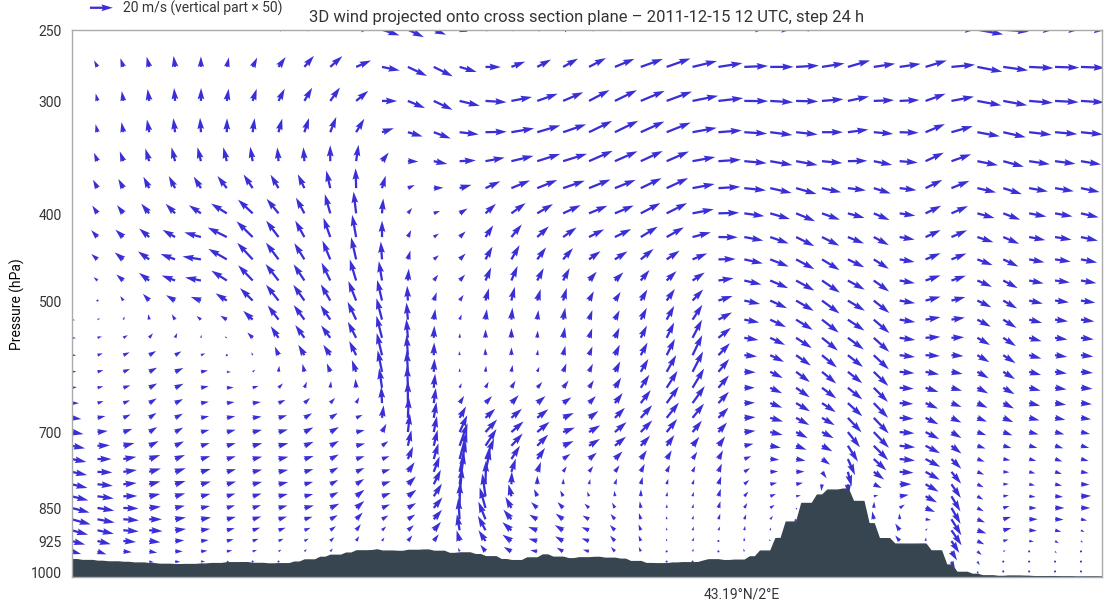

In [11]:
step = 5  # one column of arrows out of 5
cols = slice(None, None, step)
lats, lons, distance = xs_p["latitude"].values, xs_p["longitude"].values, xs_p["distance"].values
X, Y = np.meshgrid(distance[cols], xs_p["pressure"].values)  # (pressure, thinned point)
U_arrow = xs_p["wp"].values[:, cols]  # m/s, along the line (southwards)
V_arrow = 50 * xs_p["w"].values[:, cols]  # m/s, vertical velocity times 50, up

chart = ekp.Subplot(figsize=(11, 6))
ax = chart.ax
arrows = ax.quiver(X, Y, U_arrow, V_arrow, color="#3a2fd6", angles="uv", scale=900, width=0.0022)
ax.quiverkey(arrows, 0.04, 1.04, 20, "20 m/s (vertical part × 50)", coordinates="axes", labelpos="E")
# orography: charcoal polygon from the surface pressure down to 1015 hPa, drawn on top
chart.fill_between(xs_p["sp"], 1015, x=xs_p["distance"], color="#36454f", alpha=1)

# one tick where the line crosses 2°E (lons increase along the line)
tick_distance = np.interp(2.0, lons, distance)
tick_lat = np.interp(2.0, lons, lats)

ax.set_yscale("log")
ax.set_ylim(1015, 250)  # 1015 hPa at the bottom, 250 hPa at the top
pressure_ticks = [1000, 925, 850, 700, 500, 400, 300, 250]
ax.set_yticks(pressure_ticks)
ax.set_yticklabels([str(p) for p in pressure_ticks])
ax.minorticks_off()
ax.set_xlim(distance[0], distance[-1])
ax.set_xticks([tick_distance])
ax.set_xticklabels([f"{tick_lat:.2f}°N/2°E"])
ax.grid(False)  # no grid lines over the arrows, as in Metview
ax.set_ylabel("Pressure (hPa)")
ax.set_title("3D wind projected onto cross section plane – 2011-12-15 12 UTC, step 24 h")

chart.show()